# Member 1 — Clustering Track: Evaluation and Visualisation (Gas Sensor Array Drift)

**Review 2 scope (Member 1):** clustering deliverables **B2** (Silhouette, Davies-Bouldin and Calinski-Harabasz
for every algorithm, Elbow curve for K-Means, Dendrogram for Hierarchical clustering) and **B3** (PCA 2-D scatter
plot for every algorithm, t-SNE plot).

- Dataset: UCI *Gas Sensor Array Drift at Different Concentrations* — 13,910 measurements, 128 features
  (16 chemical sensors x 8 features each), 6 gases.
- Clustering is unsupervised: the gas label (`class`) and `concentration` are **removed before fitting** and used
  only afterwards to interpret the clusters.
- `random_state=42` everywhere. Every plot has a title, labelled axes and a legend; palettes are colour-blind safe.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', palette='colorblind')
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning'
warnings.filterwarnings('ignore', category=UserWarning)

RESULTS_DIR = Path('../results/clustering')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / name, dpi=150, bbox_inches='tight')

## 1. Load data and build the feature matrix

The raw data is the ten `batch*.dat` files converted to one CSV by `data/raw/gassensor/convert_gas_sensor.py`.

In [2]:
df = pd.read_csv('../data/raw/gassensor/gas_sensor/gas_sensor.csv')
GAS_NAMES = {1: 'Ethanol', 2: 'Ethylene', 3: 'Ammonia', 4: 'Acetaldehyde', 5: 'Acetone', 6: 'Toluene'}

y_gas = df['class'].map(GAS_NAMES)            # kept aside, used only for interpretation
X_raw = df.drop(columns=['class', 'concentration'])

print('shape:', df.shape, '| features used for clustering:', X_raw.shape[1])
print('missing values:', int(df.isna().sum().sum()), '| duplicate rows:', int(df.duplicated().sum()))
skew = X_raw.skew().abs()
print('median |skewness| of the features: %.1f | features with |skewness| > 5: %d' % (skew.median(), (skew > 5).sum()))
display(y_gas.value_counts().rename('measurements').to_frame())

shape: (13910, 130) | features used for clustering: 128
missing values: 0 | duplicate rows: 0
median |skewness| of the features: 2.4 | features with |skewness| > 5: 36


,measurements
class,
Acetone,3009
Ethylene,2926
Ethanol,2565
Acetaldehyde,1936
Toluene,1833
Ammonia,1641


### 1.1 Scaling

Two steps, both justified by the data:
1. **Signed log transform** `sign(x) * log1p(|x|)`. The features mix raw resistance changes in the tens of
   thousands with small transient slopes, many of them negative and heavily skewed. The signed log keeps the sign
   and compresses the long tails, so a handful of extreme readings do not dominate the distances.
2. **`StandardScaler`** so each of the 128 features has mean 0 and variance 1. K-Means and Ward linkage use
   Euclidean distance; without scaling the resistance features (~10^4) would decide every cluster on their own.

There is no train/test split in clustering, so the scaler is fitted on the whole feature matrix. No label
information enters this step.

In [3]:
X_log = np.sign(X_raw) * np.log1p(X_raw.abs())
X = StandardScaler().fit_transform(X_log)
print('scaled matrix:', X.shape, '| max |skewness| before: %.1f, after signed log: %.1f'
      % (X_raw.skew().abs().max(), X_log.skew().abs().max()))

scaled matrix: (13910, 128) | max |skewness| before: 117.9, after signed log: 6.2


In [4]:
def cluster_scores(X, labels):
    """The three internal metrics required for every algorithm."""
    return {
        'n_clusters': len(np.unique(labels)),
        'silhouette': silhouette_score(X, labels, random_state=RANDOM_STATE),
        'davies_bouldin': davies_bouldin_score(X, labels),
        'calinski_harabasz': calinski_harabasz_score(X, labels),
    }

## 2. K-Means: Elbow curve (B2)

K-Means is fitted for k = 2 ... 10 (`n_init=10`). The **Elbow curve** plots inertia (within-cluster sum of squared
distances) against k: inertia always falls as k grows, so the useful k is where the curve bends and extra clusters
stop paying off. The bend is located with the *maximum distance to the chord* rule (the point furthest from the
straight line joining the first and last points), and the silhouette score is plotted next to it as a second opinion.

In [5]:
K_RANGE = range(2, 11)
elbow_rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    elbow_rows.append({'k': k, 'inertia': km.inertia_,
                       'silhouette': silhouette_score(X, km.labels_, random_state=RANDOM_STATE)})
elbow = pd.DataFrame(elbow_rows).set_index('k')

def elbow_point(x, y):
    """Index of the point furthest from the chord joining the first and last points."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn, yn = (x - x[0]) / (x[-1] - x[0]), (y - y[-1]) / (y[0] - y[-1])
    return int(np.argmax(np.abs(yn - (1 - xn))))

K_BEST = int(elbow.index[elbow_point(elbow.index, elbow['inertia'])])
print('elbow at k =', K_BEST)
display(elbow.round(3))

elbow at k = 4


,inertia,silhouette
k,,
2,1057752.083,0.345
3,875096.844,0.320
4,729789.783,0.267
5,662613.702,0.229
6,609723.003,0.250
7,564912.178,0.233
8,523216.601,0.224
9,497447.492,0.210
10,473073.692,0.211


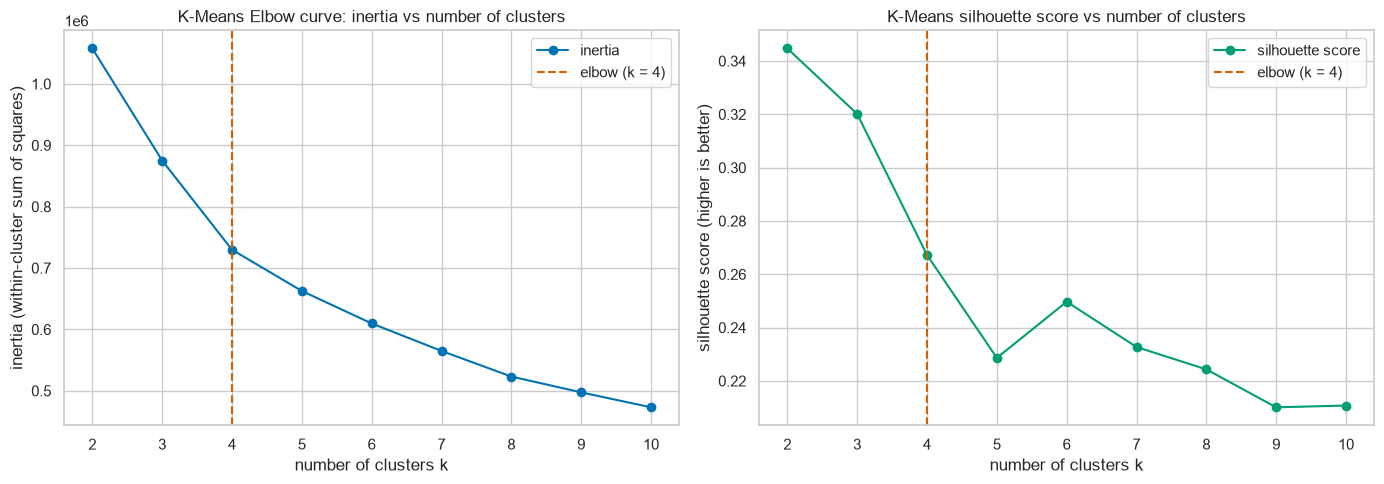

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(elbow.index, elbow['inertia'], marker='o', label='inertia')
axes[0].axvline(K_BEST, color='C3', ls='--', label=f'elbow (k = {K_BEST})')
axes[0].set_title('K-Means Elbow curve: inertia vs number of clusters')
axes[0].set_xlabel('number of clusters k')
axes[0].set_ylabel('inertia (within-cluster sum of squares)')
axes[0].legend()

axes[1].plot(elbow.index, elbow['silhouette'], marker='o', color='C2', label='silhouette score')
axes[1].axvline(K_BEST, color='C3', ls='--', label=f'elbow (k = {K_BEST})')
axes[1].set_title('K-Means silhouette score vs number of clusters')
axes[1].set_xlabel('number of clusters k')
axes[1].set_ylabel('silhouette score (higher is better)')
axes[1].legend()
save_fig('kmeans_elbow_silhouette.png')
plt.show()

**Observation.**
- Inertia drops fast up to k = 4 (1.06M -> 0.73M) and then falls in smaller, nearly even steps (0.73M -> 0.47M over
  six more clusters). The chord rule puts the elbow at **k = 4**.
- Silhouette is highest at k = 2 (0.345) and keeps falling, with a small bump at k = 6 (0.250). A high k = 2 silhouette
  is common: splitting into two big halves is easy, but it says little about the data's finer structure.
- k = 4 is used for both algorithms. It is where adding clusters stops paying off in inertia, and its silhouette
  (0.267) is still well above the k >= 7 values.

In [7]:
kmeans = KMeans(n_clusters=K_BEST, n_init=10, random_state=RANDOM_STATE).fit(X)
labels = {'K-Means': kmeans.labels_}
print('K-Means cluster sizes:', np.bincount(kmeans.labels_).tolist())

K-Means cluster sizes: [4653, 3766, 2486, 3005]
